In [1]:
# Student Name: Amelia Hamulewicz
# Student Number: C00296605
# Date: 06/10/2026

# Exploring Irish Property Prices 2010 - 2024
As a student living in Ireland, I chose to research the rising housing prices in Ireland, and what it could mean for buying a house in the future. 
This dataset includes houses and apartments.

**1.** How did median recorded residential sale prices change between 2010 and 2024? <br>
**2.** How accurately can Linear and Polynomial regression predict median prices for 2023 and 2024?<br>
&emsp;**2a.** For all residential properties? <br>
&emsp;**2b.** For new properties? <br>
&emsp;**2c.** For second-hand properties?<br>
**3.** How did the number of recorded sale entries change each year? <br>
**4.** Can clustering identify counties with similar prices and percentage price changes?<br>

In my examples, I will use the median sale price for each year.

### Lets begin with the standard imports:

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

### Loading the dataset
Now lets load the [Irish Housing Prices dataset](https://www.kaggle.com/datasets/fionnhughes/property-price-register) by FionnHughes, that I found on Kaggle.

I will use **date_of_sale** to group entries by year. I will create **price_with_vat** for the price comparisons, keeping the original **price_eur** unchanged.

In [3]:
house_data = pd.read_csv('property_price_register.csv', low_memory=False)
print('House data:', house_data.columns.tolist())

House data: ['date_of_sale', 'address', 'county', 'eircode', 'price_eur', 'not_full_market_price', 'vat_exclusive', 'description', 'property_size']


In [4]:
display(house_data.head()) # Show the first five rows

,date_of_sale,address,county,eircode,price_eur,not_full_market_price,vat_exclusive,description,property_size
0,2010-01-01,"5 Braemor Drive, Churchtown, Co.Dublin",Dublin,NaN,343000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
1,2010-01-03,"134 Ashewood Walk, Summerhill Lane, Portlaoise",Laois,NaN,185000.0,False,True,New Dwelling house /Apartment,greater than or equal to 38 sq metres and less...
2,2010-01-04,"59 ormond keep, nenagh",Tipperary,NaN,128000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
3,2010-01-04,"66 Rory O'Connor Place, Arklow",Wicklow,NaN,145000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
4,2010-01-04,"78 Sundays Well Road, Cork",Cork,NaN,510000.0,False,False,Second-Hand Dwelling house /Apartment,NaN



The dataset has **807,936** rows and 9 columns. Each row is a recorded property sale.
This is a large dataset, but my examples use the median house price per year. This means the examples have far fewer values to work with than the original file.

In [5]:
print('Dataset size:', house_data.shape)

Dataset size: (807936, 9)


### Checking the data
First, I will check for missing values and repeated rows. I will also look at the property descriptions and VAT flags.

I will now clean the data and reuse it for most of the questions. Missing Eircodes or property sizes will be kept because these columns are not needed. The duplicate check only counts repeated rows; it does not remove them.

In [6]:
display(house_data.isna().sum())
print('Exact duplicate rows:', house_data.duplicated().sum())
display(house_data['description'].value_counts())

display(pd.crosstab(house_data['description'], house_data['vat_exclusive']))


date_of_sale                  0
address                       0
county                        0
eircode                  556504
price_eur                     0
not_full_market_price         0
vat_exclusive                 0
description                   0
property_size            755328
dtype: int64

Exact duplicate rows: 0


description
Second-Hand Dwelling house /Apartment    663246
New Dwelling house /Apartment            144641
Teach/Árasán Cónaithe Atháimhe               45
Teach/Árasán Cónaithe Nua                     3
Teach/?ras?n C?naithe Nua                     1
Name: count, dtype: int64

vat_exclusive,False,True
description,,
New Dwelling house /Apartment,2373,142268
Second-Hand Dwelling house /Apartment,663246,0
Teach/?ras?n C?naithe Nua,0,1
Teach/Árasán Cónaithe Atháimhe,45,0
Teach/Árasán Cónaithe Nua,0,3


### Limitation found and fixed
The table above shows whether VAT is excluded from the recorded sale price. True means VAT is excluded. False means the sale is not marked as VAT-exclusive.

The VAT rate changed for some apartments in late 2025. As the dataset does not give enough detail to identify them, I will exclude 2025 and 2026 from the price comparisons.<br>

[Sources: [TaxKey](https://www.taxkey.ie/post/ireland-vat-cut-apartment-sales) and [BDO Ireland](https://www.bdo.ie/en-gb/insights/2026/9-vat-rate-for-apartments-helping-to-address-ireland%E2%80%99s-housing-crisis-through-tax-policy) ]

I will use sales from 2010–2024 and add 13.5% VAT to new-property prices marked as VAT-exclusive. 

Rows with missing values will be removed, except for missing Eircodes and property sizes. Invalid dates and prices of zero or less will also be removed.

A new column will show whether each property is new or second-hand. Only full-market-price sales will be used for all questions.

In [7]:
# Make a copy so the original data stays unchanged
houses = house_data.copy()
print('Rows before cleaning:', houses.shape[0])

# Convert the dates and prices
houses['date_of_sale'] = pd.to_datetime(
    houses['date_of_sale'], errors='coerce' #invalid or unparseable values to NaN
)
houses['price_eur'] = pd.to_numeric(
    houses['price_eur'], errors='coerce'
)

# Remove missing values, but ignore Eircode and property size
required_columns = houses.columns.drop(['eircode', 'property_size'])
houses = houses.dropna(subset=required_columns).copy()

# Remove prices of zero or less
houses = houses[houses['price_eur'] > 0].copy()
print('Rows after cleaning:', houses.shape[0])

# Get the year and keep 2010–2024
# Leave out 2025-2026 because of the VAT change 
houses['year'] = houses['date_of_sale'].dt.year
houses = houses[houses['year'].between(2010, 2024)].copy()
print('Rows in 2010–2024:', houses.shape[0])

# Keep the original price and create a VAT-adjusted price
houses['price_with_vat'] = houses['price_eur']

# Add 13.5% where VAT is excluded
add_vat = houses['vat_exclusive'] == True
houses.loc[add_vat, 'price_with_vat'] = (
    houses.loc[add_vat, 'price_eur'] * 1.135
)

# Put matching descriptions into the same group
description_groups = {
    'New Dwelling house /Apartment': 'New',
    'Second-Hand Dwelling house /Apartment': 'Second-hand',
    'Teach/Árasán Cónaithe Nua': 'New',
    'Teach/Árasán Cónaithe Atháimhe': 'Second-hand',
    'Teach/?ras?n C?naithe Nua': 'New'
}

houses['property_group'] = houses['description'].map(description_groups)

# Stop if a description has not been recognised
assert houses['property_group'].notna().all(), 'Check property descriptions'

# Keep full-market-price entries for all questions
houses = houses[
    houses['not_full_market_price'] == False
].copy()

# Count the remaining sale entries for each year
yearly_sales = houses.groupby('year').size()

print('Rows after only including full market prices:', houses.shape[0])

# Show the prepared data
display(houses.head())

Rows before cleaning: 807936
Rows after cleaning: 807936
Rows in 2010–2024: 705299
Rows after only including full market prices: 669446


,date_of_sale,address,county,eircode,price_eur,not_full_market_price,vat_exclusive,description,property_size,year,price_with_vat,property_group
0,2010-01-01,"5 Braemor Drive, Churchtown, Co.Dublin",Dublin,NaN,343000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2010,343000.0,Second-hand
1,2010-01-03,"134 Ashewood Walk, Summerhill Lane, Portlaoise",Laois,NaN,185000.0,False,True,New Dwelling house /Apartment,greater than or equal to 38 sq metres and less...,2010,209975.0,New
2,2010-01-04,"59 ormond keep, nenagh",Tipperary,NaN,128000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2010,128000.0,Second-hand
3,2010-01-04,"66 Rory O'Connor Place, Arklow",Wicklow,NaN,145000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2010,145000.0,Second-hand
4,2010-01-04,"78 Sundays Well Road, Cork",Cork,NaN,510000.0,False,False,Second-Hand Dwelling house /Apartment,NaN,2010,510000.0,Second-hand


## **1.** How did median recorded prices change?
I will use the median sale price for each year from 2010–2024, using prices that include VAT. This gives us 15 values to work with.

I chose the median because a few very expensive sales could push the average price up. The median is less affected by these sales, so it gives a better idea of a typical recorded sale price.

However it's important to note that the dataset contains different properties, which can affect the results.

### Calculating the median sale prices

In [8]:
# Calculate the median sale price for ALL properties each year
yearly_median_prices = houses.groupby('year')['price_with_vat'].median()

# Calculate the median sale price for NEW properties each year
new_houses = houses[houses['property_group'] == 'New']
new_median_prices = new_houses.groupby('year')['price_with_vat'].median()

# Calculate the median sale price for SECOND-HAND properties each year
second_hand_houses = houses[houses['property_group'] == 'Second-hand']
second_hand_median_prices = second_hand_houses.groupby('year')['price_with_vat'].median()

# Put the yearly medians into one table
group_prices = pd.DataFrame({
    'All properties': yearly_median_prices,
    'New': new_median_prices,
    'Second-hand': second_hand_median_prices
})

years = group_prices.index.values
start_year = years.min()

# Count from the first year to keep polynomial inputs small
x = years - start_year # 0, 1, 2, etc... 
xfit = np.linspace(x.min(), x.max(), 1000) # Creates 1,000 evenly spaced numbers between 0 and 14

print('Number of years:', len(x))
print('Median sale prices including VAT (€):')
display(group_prices.round(2))

Number of years: 15
Median sale prices including VAT (€):


,All properties,New,Second-hand
year,,,
2010,215587.58,215000.00,216000.0
2011,180000.00,181311.71,180000.0
2012,157999.97,167000.50,155000.0
2013,147000.00,139999.98,149492.0
2014,154000.00,165000.00,151000.0
2015,168000.00,192425.63,165000.0
2016,190000.00,272400.00,178375.0
2017,220000.00,299999.80,200000.0
2018,239999.99,330000.00,215000.0


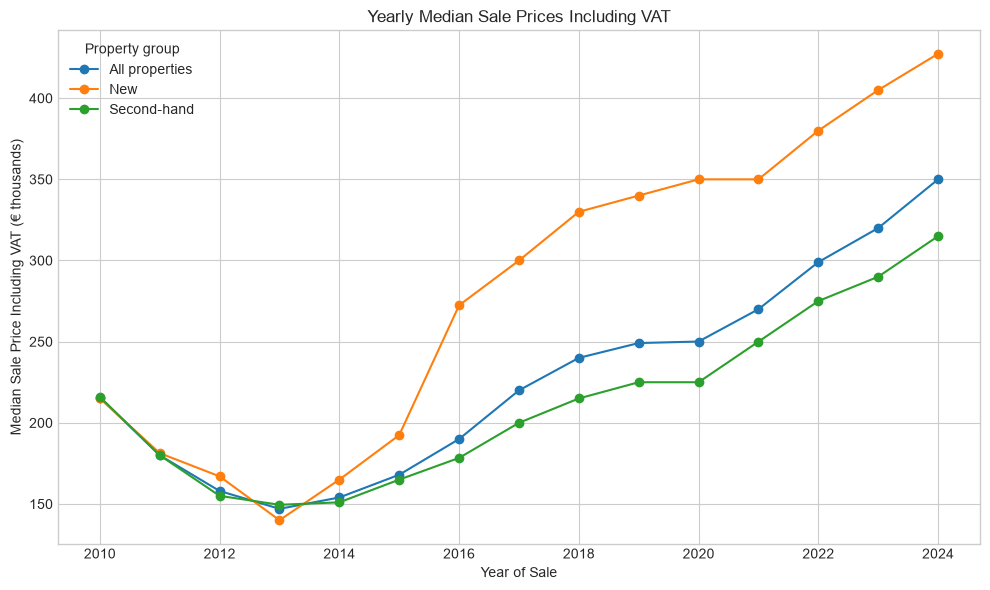

In [9]:
# Compare the yearly medians, without regression lines
(group_prices / 1000).plot(marker='o', figsize=(10, 6))
plt.xlabel('Year of Sale')
plt.ylabel('Median Sale Price Including VAT (€ thousands)')
plt.title('Yearly Median Sale Prices Including VAT')
plt.legend(title='Property group')
plt.tight_layout()
plt.show()


### Conclusion
Median prices fell until 2013 and then increased across all three groups. The median for all properties rose from about €215k in 2010 to €350k in 2024.

New properties had the biggest increase over the period. In 2024, their median was about €427,348, compared with €315,000 for second-hand properties.

The overall median includes both new and second-hand sales. Different properties were sold each year, so the graph does not track the same homes over time.

## 2. How accurately can Linear and Polynomial regression predict median prices for 2023 and 2024?
I will compare training from 2010 and 2013 for each property group. Both use 2023 and 2024 for testing. The dotted line separates the training and test years.

The loop repeats the same steps for both starting years. I will compare the average errors in one table at the end.


In [10]:
# Keep the errors from each test
prediction_errors = []


### **2a.** For all residential properties?

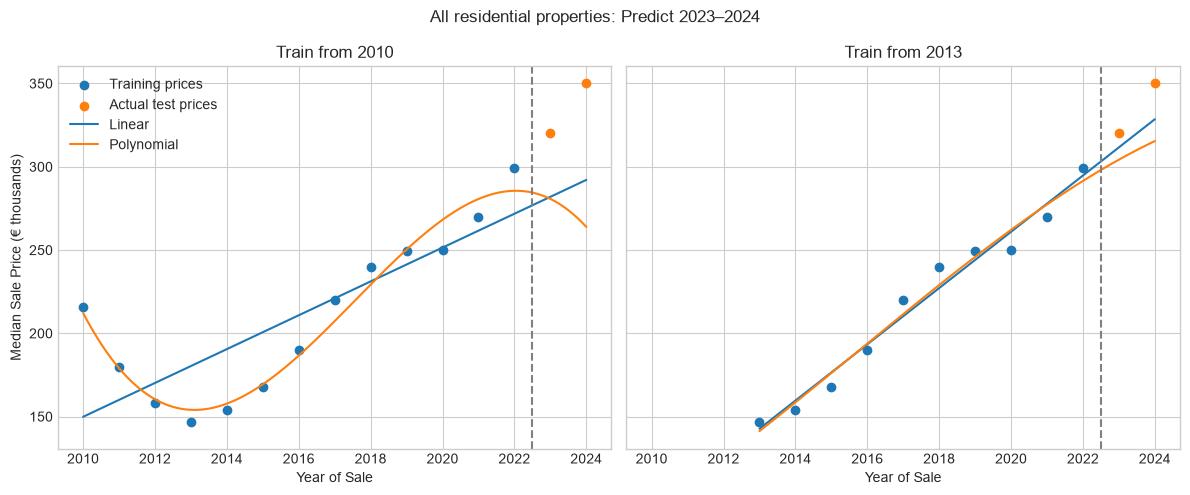

In [11]:
# Use this group's yearly medians in € thousands
prices = yearly_median_prices.values / 1000
fig, ax = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(12, 5))

for i, first_year in enumerate([2010, 2013]):
    # Train up to 2022 and test on 2023–2024
    train = (years >= first_year) & (years <= 2022)
    xtrain = x[train]
    ytrain = prices[train]
    xtest = x[-2:]
    ytest = prices[-2:]

    # Fit both models using the training years only
    model = LinearRegression()
    model.fit(xtrain[:, np.newaxis], ytrain)
    poly_model = make_pipeline(PolynomialFeatures(3), LinearRegression())
    poly_model.fit(xtrain[:, np.newaxis], ytrain)

    # Draw the fitted lines and show the test prices
    xfit = np.linspace(xtrain.min(), xtest.max(), 1000)
    ax[i].scatter(years[train], ytrain, label='Training prices')
    ax[i].scatter(years[-2:], ytest, label='Actual test prices')
    ax[i].plot(xfit + start_year,
               model.predict(xfit[:, np.newaxis]), label='Linear')
    ax[i].plot(xfit + start_year,
               poly_model.predict(xfit[:, np.newaxis]), label='Polynomial')
    ax[i].axvline(2022.5, color='grey', linestyle='--')
    ax[i].set_title('Train from ' + str(first_year))
    ax[i].set_xlabel('Year of Sale')

    # Save the average prediction errors in euros
    linear_prices = model.predict(xtest[:, np.newaxis])
    poly_prices = poly_model.predict(xtest[:, np.newaxis])
    prediction_errors.append({
        'Group': 'All residential properties',
        'Training period': str(first_year) + '–2022',
        'Linear error (€)': np.mean(np.abs(ytest - linear_prices)) * 1000,
        'Polynomial error (€)': np.mean(np.abs(ytest - poly_prices)) * 1000
    })

ax[0].set_ylabel('Median Sale Price (€ thousands)')
ax[0].legend()
fig.suptitle('All residential properties: Predict 2023–2024')
plt.tight_layout()
plt.show()

### **2b.** For new properties? 

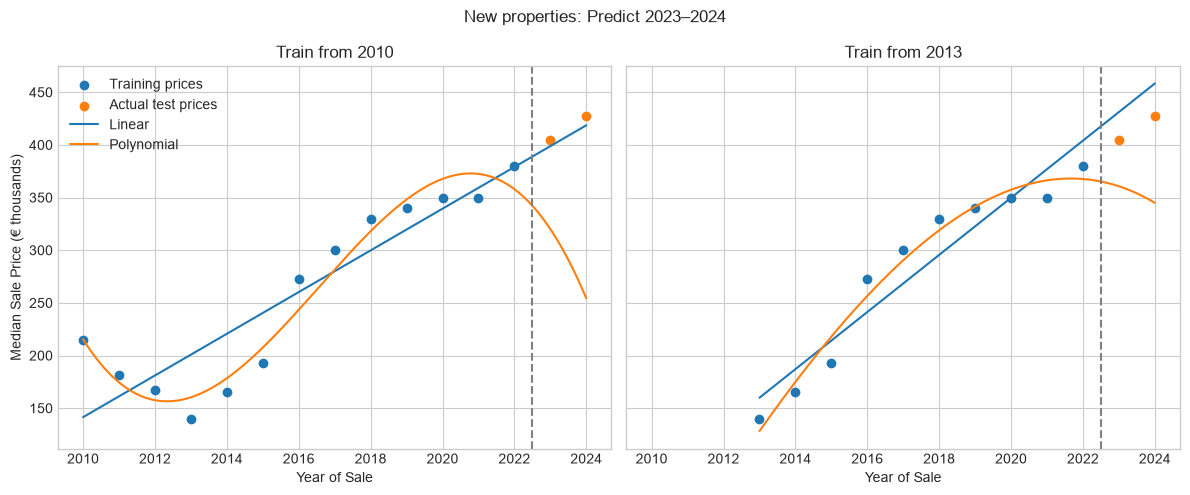

In [12]:
# Use this group's yearly medians in € thousands
prices = new_median_prices.values / 1000
fig, ax = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(12, 5))

for i, first_year in enumerate([2010, 2013]):
    # Train up to 2022 and test on 2023–2024
    train = (years >= first_year) & (years <= 2022)
    xtrain = x[train]
    ytrain = prices[train]
    xtest = x[-2:]
    ytest = prices[-2:]

    # Fit both models using the training years only
    model = LinearRegression()
    model.fit(xtrain[:, np.newaxis], ytrain)
    poly_model = make_pipeline(PolynomialFeatures(3), LinearRegression())
    poly_model.fit(xtrain[:, np.newaxis], ytrain)

    # Draw the fitted lines and show the test prices
    xfit = np.linspace(xtrain.min(), xtest.max(), 1000)
    ax[i].scatter(years[train], ytrain, label='Training prices')
    ax[i].scatter(years[-2:], ytest, label='Actual test prices')
    ax[i].plot(xfit + start_year,
               model.predict(xfit[:, np.newaxis]), label='Linear')
    ax[i].plot(xfit + start_year,
               poly_model.predict(xfit[:, np.newaxis]), label='Polynomial')
    ax[i].axvline(2022.5, color='grey', linestyle='--')
    ax[i].set_title('Train from ' + str(first_year))
    ax[i].set_xlabel('Year of Sale')

    # Save the average prediction errors in euros
    linear_prices = model.predict(xtest[:, np.newaxis])
    poly_prices = poly_model.predict(xtest[:, np.newaxis])
    prediction_errors.append({
        'Group': 'New properties',
        'Training period': str(first_year) + '–2022',
        'Linear error (€)': np.mean(np.abs(ytest - linear_prices)) * 1000,
        'Polynomial error (€)': np.mean(np.abs(ytest - poly_prices)) * 1000
    })

ax[0].set_ylabel('Median Sale Price (€ thousands)')
ax[0].legend()
fig.suptitle('New properties: Predict 2023–2024')
plt.tight_layout()
plt.show()


### **2c.** For second-hand properties?

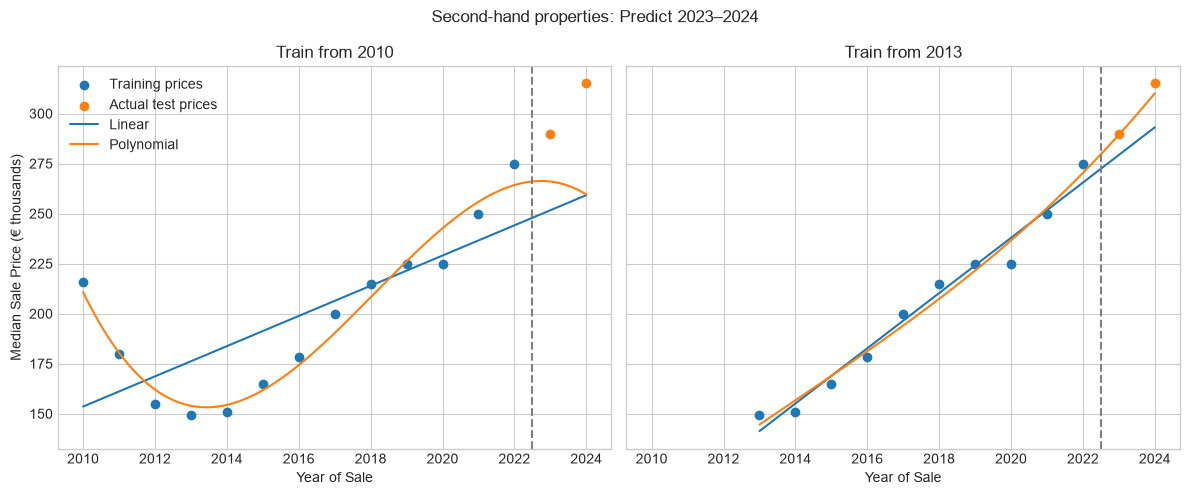

In [13]:
# Use this group's yearly medians in € thousands
prices = second_hand_median_prices.values / 1000
fig, ax = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(12, 5))

for i, first_year in enumerate([2010, 2013]):
    # Train up to 2022 and test on 2023–2024
    train = (years >= first_year) & (years <= 2022)
    xtrain = x[train]
    ytrain = prices[train]
    xtest = x[-2:]
    ytest = prices[-2:]

    # Fit both models using the training years only
    model = LinearRegression()
    model.fit(xtrain[:, np.newaxis], ytrain)
    poly_model = make_pipeline(PolynomialFeatures(3), LinearRegression())
    poly_model.fit(xtrain[:, np.newaxis], ytrain)

    # Draw the fitted lines and show the test prices
    xfit = np.linspace(xtrain.min(), xtest.max(), 1000)
    ax[i].scatter(years[train], ytrain, label='Training prices')
    ax[i].scatter(years[-2:], ytest, label='Actual test prices')
    ax[i].plot(xfit + start_year,
               model.predict(xfit[:, np.newaxis]), label='Linear')
    ax[i].plot(xfit + start_year,
               poly_model.predict(xfit[:, np.newaxis]), label='Polynomial')
    ax[i].axvline(2022.5, color='grey', linestyle='--')
    ax[i].set_title('Train from ' + str(first_year))
    ax[i].set_xlabel('Year of Sale')

    # Save the average prediction errors in euros
    linear_prices = model.predict(xtest[:, np.newaxis])
    poly_prices = poly_model.predict(xtest[:, np.newaxis])
    prediction_errors.append({
        'Group': 'Second-hand properties',
        'Training period': str(first_year) + '–2022',
        'Linear error (€)': np.mean(np.abs(ytest - linear_prices)) * 1000,
        'Polynomial error (€)': np.mean(np.abs(ytest - poly_prices)) * 1000
    })

ax[0].set_ylabel('Median Sale Price (€ thousands)')
ax[0].legend()
fig.suptitle('Second-hand properties: Predict 2023–2024')
plt.tight_layout()
plt.show()


### Comparing the errors
The mean absolute error is the average difference between the predicted and actual median prices in euros. Lower values mean closer predictions.

In [14]:
# Lower average error means closer predictions
comparison = pd.DataFrame(prediction_errors)
display(comparison.round(2))

,Group,Training period,Linear error (€),Polynomial error (€)
0,All residential properties,2010–2022,47968.19,62714.15
1,All residential properties,2013–2022,14906.55,25146.75
2,New properties,2010–2022,7456.78,129045.63
3,New properties,2013–2022,28560.28,63327.13
4,Second-hand properties,2010–2022,47062.81,39742.20
5,Second-hand properties,2013–2022,16297.05,2755.79


### Overall conclusion
For **all properties**, linear regression trained from 2013 was closest, with an average error of about €14,907. For **new properties**, linear regression trained from 2010 was better, with an error of about €7,457. For **second-hand properties**, polynomial regression trained from 2013 was closest, with an error of about €2,756.

Starting later did not improve every model. These results only cover 2023 and 2024, so they may differ for other years. 

In [15]:
### MIGHT DO GAUSSIAN, LASSO AND RIDGE LATER TO SEE IF THEY IMPROVES PRICE PREDICTIONS

## **3.** How did the number of recorded full-market-price sale entries change?
I will count the sale entries for each year from 2010–2024. These are the same entries used in the price analysis.

,All properties,New,Second-hand
year,,,
2010,19814,5156,14658
2011,17336,2814,14522
2012,23648,3017,20631
2013,28340,3609,24731
2014,42532,5325,37207
2015,47444,6129,41315
2016,47939,6641,41298
2017,52290,9096,43194
2018,54104,10569,43535


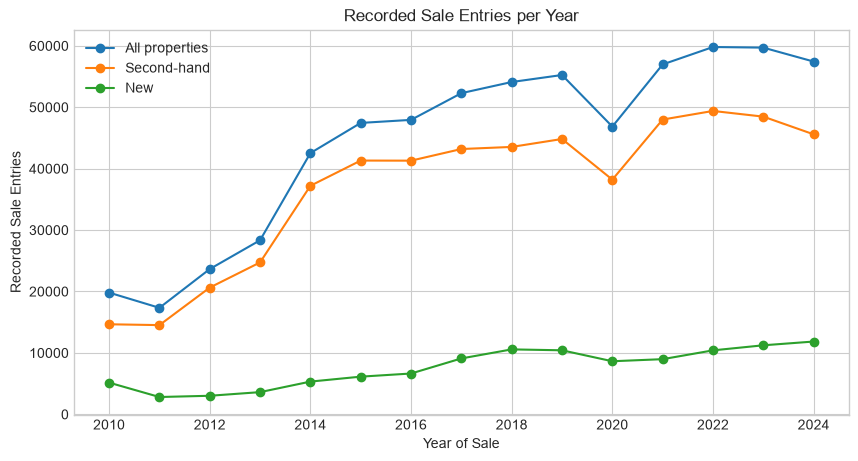

In [16]:
# Count sale entries for each year
yearly_sales = houses.groupby('year').size()
new_sales = new_houses.groupby('year').size()
second_hand_sales = second_hand_houses.groupby('year').size()

sale_counts = pd.DataFrame({
    'All properties': yearly_sales,
    'New': new_sales,
    'Second-hand': second_hand_sales
})

display(sale_counts)
# Compare the three groups
plt.figure(figsize=(10, 5))
plt.plot(yearly_sales.index, yearly_sales.values, marker='o', label='All properties')
plt.plot(second_hand_sales.index, second_hand_sales.values, marker='o', label='Second-hand')
plt.plot(new_sales.index, new_sales.values, marker='o', label='New')

plt.xlabel('Year of Sale')
plt.ylabel('Recorded Sale Entries')
plt.title('Recorded Sale Entries per Year')
plt.legend()
plt.show()

### Observation
Recorded sales increased overall, but not every year. The lowest count was in 2011 and the highest was in 2022, with a noticeable drop in 2020.

Second-hand properties made up most sales. After 2022, their count fell while new-property sales continued to rise, showing that the two groups did not always follow the same pattern.

## 4. Can clustering identify counties with similar prices and percentage price changes?

Each point will be one county. I will use its average yearly median price and average annual percentage change across 2010–2024.

First, I will calculate each **county's median price** for every year. Then I will **average** the 15 **medians** and the 14 year-to-year **percentage changes**. Each year gets equal weight. The percentage is an average annual change.

I will use the same VAT-adjusted, full-market-price sales as before. 

In [17]:
# Calculate each county's median price for every year
county_yearly = houses.groupby(
    ['county', 'year']
)['price_with_vat'].median().unstack()

# Keep counties with all 15 yearly medians
county_yearly = county_yearly.reindex(columns=range(2010, 2025)).dropna()

# Calculate the percentage change from one year to the next
county_changes = county_yearly.pct_change(axis=1, fill_method=None) * 100

# Average the 15 yearly medians and 14 annual percentage changes
county_prices = pd.DataFrame({
    'Average yearly median (€)': county_yearly.mean(axis=1),
    'Average annual change (%)': county_changes.iloc[:, 1:].mean(axis=1)
})
print('Number of counties:', len(county_prices))


Number of counties: 26


In [18]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Scale euros and percentages so both features contribute
scaler = StandardScaler()
X = scaler.fit_transform(county_prices)

# Fit K-means using the lab structure
kmeans = KMeans(n_clusters=3, random_state=0, n_init=10)
kmeans.fit(X)
y_kmeans = kmeans.predict(X)


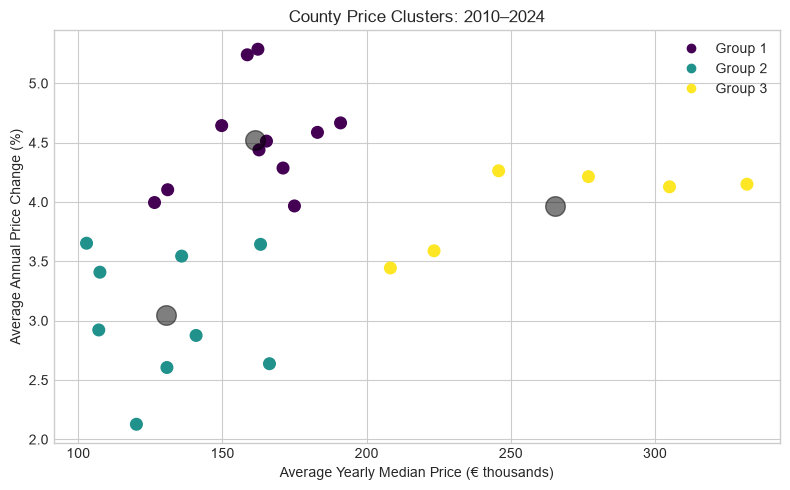

In [19]:
# Plot the counties coloured by their groups
plt.figure(figsize=(8, 5))
points = plt.scatter(county_prices['Average yearly median (€)'] / 1000,
                     county_prices['Average annual change (%)'],
                     c=y_kmeans, s=70, cmap='viridis')

# Show the centres in the original units
centres = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centres[:, 0] / 1000, centres[:, 1],
            c='black', s=200, alpha=0.5)

plt.xlabel('Average Yearly Median Price (€ thousands)')
plt.ylabel('Average Annual Price Change (%)')
plt.title('County Price Clusters: 2010–2024')
plt.legend(points.legend_elements()[0], ['Group 1', 'Group 2', 'Group 3'])
plt.margins(x=0.05, y=0.05)
plt.tight_layout()
plt.show()


Each dot is one county. The colours show the groups and the larger black dots show their centres.

In [20]:
# Show which counties belong to each group
county_results = county_prices.copy()
county_results['Group'] = y_kmeans + 1
display(county_results.sort_values('Group').round(2))

# Summarise each group
cluster_summary = county_results.groupby('Group').agg(
    Counties=('Average yearly median (€)', 'size'),
    Average_median_price=('Average yearly median (€)', 'mean'),
    Average_annual_change=('Average annual change (%)', 'mean')
)
display(cluster_summary.round(2))


,Average yearly median (€),Average annual change (%),Group
county,,,
Cavan,126436.67,4.00,1
Clare,162670.26,4.44,1
Laois,158601.56,5.24,1
Kilkenny,182941.67,4.59,1
Limerick,174958.70,3.97,1
Louth,190952.54,4.67,1
Westmeath,162293.28,5.29,1
Offaly,149731.67,4.64,1
Sligo,131002.00,4.10,1


,Counties,Average_median_price,Average_annual_change
Group,,,
1,11,161441.01,4.52
2,9,130510.28,3.05
3,6,265202.50,3.96


### Conclusion

**Group 1** had an **average price** of about €161,441, but the **highest average annual growth** at 4.5%. 
It included:
- Mayo
- Longford
- Leitrim
- Donegal
- Kerry
- Monaghan
- Tipperary
- Carlow

**Group 2** had the **lowest average price** of €130,510 and **growth** of about 3.0%. 
It included:
- Cavan
- Clare
- Laois
- Kilkenny
- Limmerick
- Louth
- Westmeath
- Offaly
- Sligo
- Waterford
- Wexford

**Group 3** had the **highest average** yearly median price, about €265,203, and **average annual growth** of about 4.0%. 
It included:
- Kildare
- Cork
- Dublin
- Galway
- Meath
- Wicklow

The groups show that similar average prices do not always mean similar growth. The membership table identifies which counties shared both characteristics.